# Class Activity: "Be the Agent" on CartPole

**Format:** pairs | **Environment:** `rl-gym` conda env | **Duration:** one class session

## Learning goals
- Identify the 4 state variables and the 2 actions.
- Understand the reward and the termination and truncation conditions.
- Build intuition for why a policy is needed before introducing DQN.

In [1]:
import numpy as np
import gymnasium as gym
import matplotlib.pyplot as plt

SEED = 0
np.random.seed(SEED)

## Part 1: Predict before you run 
Inspect the spaces and the outputs of `reset()` and `step()`, then fill in the table below.

In [2]:
env = gym.make("CartPole-v1")
print("Observation space:", env.observation_space)
print("Action space:", env.action_space)

obs, info = env.reset(seed=SEED)
print("reset ->", obs, info)

obs, reward, terminated, truncated, info = env.step(0)
print("step(0) ->", obs, reward, terminated, truncated, info)
obs, reward, terminated, truncated, info = env.step(1)
print("step(1) ->", obs, reward, terminated, truncated, info)

Observation space: Box([-4.8               -inf -0.41887903        -inf], [4.8               inf 0.41887903        inf], (4,), float32)
Action space: Discrete(2)
reset -> [ 0.01369617 -0.02302133 -0.04590265 -0.04834723] {}
step(0) -> [ 0.01323574 -0.21745604 -0.04686959  0.22950698] 1.0 False False {}
step(1) -> [ 0.00888662 -0.02169675 -0.04227945 -0.0775841 ] 1.0 False False {}


| Index | Variable | Meaning | Units | Termination limit |
|---|---|---|---|---|
| 0 | Cart position | Horizontal position of the cart on the track (0 = center) | meters (m) | ±2.4 |
| 1 | Cart velocity | How fast the cart moves along the track (negative = left, positive = right) | m/s | none |
| 2 | Pole angle | Tilt of the pole from vertical (0 = upright, positive = leaning right) | radians (rad) | ±12° (~0.21 rad) |
| 3 | Pole angular velocity | How fast the pole is tipping over (positive = falling right) | rad/s | none |

**Questions**
1. What does action 0 do? What does action 1 do?
2. What reward is given per step?
3. When does the episode end?

*Your answers:*
- Action 0 pushes the cart to the **left** and action 1 pushes it to the **right** (a fixed force of 10 N). The output confirms it: after `step(0)` the cart velocity went from -0.023 to -0.217 (accelerated left), and after `step(1)` it went back up to -0.022 (accelerated right).
- Reward is **+1 for every step** the pole stays up, including the step on which it falls. The goal is therefore to survive as long as possible. The max return is 500 in v1.
- The episode ends in two ways. **Terminated**: the pole angle exceeds ±12° (~0.21 rad) or the cart position exceeds ±2.4 (the cart leaves the track). **Truncated**: the time limit is reached, 500 steps in CartPole-v1 (200 in v0). Truncation is not a failure, it is just the clock running out.

## Part 2: Human agent
Play the game by typing actions (`0` = left, `1` = right). Use a Jupyter-friendly input prompt; press Enter on an empty line to quit.

> Requires a display. If rendering fails, remove `render_mode="human"` and rely on the printed state.

In [3]:
def play_human(seed=0, render=True):
    #env = gym.make("CartPole-v1", render_mode="human" if render else None)
    env = gym.make("CartPole-v1")

    obs, _ = env.reset(seed=seed)
    total, done = 0.0, False
    while not done:
        print(np.round(obs, 3))
        answer = input("0=left, 1=right (Enter to quit): ").strip()
        print("Action:", answer)
        if answer not in ("0", "1"):
            break
        obs, r, terminated, truncated, _ = env.step(int(answer))
        total += r
        done = terminated or truncated
    env.close()
    
    print("Score:", total)

play_human()

[ 0.014 -0.023 -0.046 -0.048]
Action: 
Score: 0.0


**Reflection**
- Which variable did you watch most? Which one did you ignore?
- Why is it hard to play with only position information?

*Your answers:*
- The most useful variables are the **pole angle** and the **pole angular velocity**, because they tell you whether the pole is falling and how fast. The one that matters least is **cart position**, since the cart has 2.4 m of room either way and only becomes relevant late in a long episode. In the printed run, the angular velocity flipped sign (-0.048, +0.23, -0.078, ...) with each alternating push, and the final pushes made it drift to -0.74 and the pole fell. The score was 8 before the episode was quit. (Edit this to reflect what you personally watched.)
- Position says nothing about the pole, which is the thing that makes the episode fail. It also gives no sense of **direction or speed**: the same position can be reached while the pole is recovering or while it is already falling. You need velocity-type information to predict where the system is going, and to react before the angle crosses the limit.

## Part 3: Design a rule-based policy
A policy is a function `policy(obs) -> action`. Evaluate each over 20 episodes.

In [4]:
def evaluate_policy(policy_fn, n_episodes=20, env_id="CartPole-v1", seed=0, **make_kwargs):
    env = gym.make(env_id, **make_kwargs)
    returns = []
    for ep in range(n_episodes):
        obs, _ = env.reset(seed=seed + ep)
        total, done = 0.0, False
        while not done:
            obs, r, terminated, truncated, _ = env.step(policy_fn(obs))
            total += r
            done = terminated or truncated
        returns.append(total)
    env.close()
    return float(np.mean(returns)), float(np.std(returns))

rng = np.random.default_rng(SEED)

def random_policy(obs):
    return int(rng.integers(2))

print("Random baseline (mean, std):", evaluate_policy(random_policy))

Random baseline (mean, std): (22.9, 13.356271934937533)


In [5]:
# obs = [cart_pos, cart_vel, pole_angle, pole_ang_vel]
def policy_angle(obs):
    return 0 if obs[2] < 0 else 1

def policy_ang_vel(obs):
    return 0 if obs[3] < 0 else 1

K = 1.0  # TODO: tune
def policy_combined(obs):
    return 0 if obs[2] + K * obs[3] < 0 else 1

# TODO: write your own policy
def policy_mine(obs):
    raise NotImplementedError

policies = {
    "random": random_policy,
    "angle": policy_angle,
    "angular velocity": policy_ang_vel,
    "angle + k*ang_vel": policy_combined,
}
for name, fn in policies.items():
    mean, std = evaluate_policy(fn)
    print(f"{name:20s} mean={mean:7.1f} std={std:6.1f}")

random               mean=   24.0 std=   8.2
angle                mean=   40.9 std=   7.4
angular velocity     mean=  198.7 std=  36.3
angle + k*ang_vel    mean=  491.7 std=  36.2


| Policy | Variables used | Mean return | Std | Why it works or fails |
|---|---|---|---|---|
| random | none | 24.0 | 8.2 | Actions ignore the state, so pushes cancel out randomly and the pole falls in ~20 steps. This is the baseline. |
| angle | pole angle | 40.9 | 7.4 | Pushes toward the side the pole leans, which is the right idea. But it only reacts to where the pole *is*, not where it is *going*, so it overshoots and oscillates with growing amplitude until it falls. |
| angular velocity | pole angular velocity | 198.7 | 36.3 | Reacts to the direction of tipping, so it damps the fall. It cannot see the absolute angle, so the pole slowly drifts away from vertical (and the cart drifts off the track) over time. |
| angle + k*ang_vel | pole angle and angular velocity (K=1) | 491.7 | 36.2 | Combines position and trend of the pole, like a PD controller: the angle term corrects the lean and the velocity term anticipates and damps overshoot. Near the 500 cap. |
| my policy | not implemented (`policy_mine` still raises `NotImplementedError`) | – | – | Write it, add it to the `policies` dict, and fill this row. Ideas: tune K, or add cart position and velocity terms to keep the cart centered. |

Note: the random row varies between runs because `rng` is shared and stateful (the first call printed 22.9 ± 13.4, the second 24.0 ± 8.2).

## Part 4: Break the environment
Pick **one** experiment and report back to the class.

The cell only prints one initial state. To measure the effect, pass the same options to env.reset() inside evaluate_policy() and compare returns for the default and wide ranges

In [6]:
# Experiment A: larger initial-state noise (default is +/-0.05)
env = gym.make("CartPole-v1")
obs, _ = env.reset(seed=SEED, options={"low": -0.3, "high": 0.3})
print("Initial state with larger noise:", obs)
env.close()

Initial state with larger noise: [ 0.08217701 -0.13812797 -0.2754159  -0.2900834 ]


In [7]:
# Experiment B: change termination thresholds
env = gym.make("CartPole-v1")
env.unwrapped.theta_threshold_radians = 0.4  # default ~0.2095
env.unwrapped.x_threshold = 4.8              # default 2.4
obs, _ = env.reset(seed=SEED)
done, steps = False, 0
while not done:
    obs, r, terminated, truncated, _ = env.step(policy_combined(obs))
    steps += 1
    done = terminated or truncated
print("Steps survived:", steps, "| terminated:", terminated, "| truncated:", truncated)
env.close()

Steps survived: 500 | terminated: False | truncated: True


In [8]:
# Experiment C: remove one variable from the policy and observe the degradation
def policy_no_vel(obs):
    return 0 if obs[2] < 0 else 1

print("full policy   :", evaluate_policy(policy_combined))
print("without ang_vel:", evaluate_policy(policy_no_vel))

full policy   : (491.7, 36.178861231387586)
without ang_vel: (40.9, 7.38173421358423)


In [9]:
# Experiment D: CartPole-v0 (200 steps) vs v1 (500 steps): truncation vs termination
for env_id in ("CartPole-v0", "CartPole-v1"):
    print(env_id, evaluate_policy(policy_combined, env_id=env_id))

CartPole-v0 (200.0, 0.0)
CartPole-v1 (491.7, 36.178861231387586)


c:\Dev\ai\ai-playground\.venv\Lib\site-packages\gymnasium\envs\registration.py:513: DeprecationWarning: WARN: The environment CartPole-v0 is out of date. You should consider upgrading to version `v1`.
  logger.deprecation(


*Experiment chosen and findings:*

- **Experiment C (remove a variable) and D (v0 vs v1)**, using the printed results:
  - **C:** the full policy (angle + ang_vel) scored **491.7**, while removing angular velocity dropped it to **40.9**. A single missing variable cut performance by more than 10x, so the velocity information is essential.
  - **D:** CartPole-v0 gave **200.0 ± 0.0**, v1 gave **491.7 ± 36.2**. The same policy is never terminated in v0; it simply hits the 200-step time limit every time (zero std). This is **truncation, not failure**, so the score reflects the time limit rather than skill.
  - **B** (for reference): with the thresholds widened (angle 0.4 rad, x 4.8) the policy survived all 500 steps and was truncated, so looser termination limits make the task easier.
  - **A** only prints one noisy initial state (angle -0.275, already past the 0.21 limit's neighborhood). To measure its effect, pass `options={"low": -0.3, "high": 0.3}` to `env.reset()` inside `evaluate_policy`.

## Part 5: Debrief and bridge to DQN
Discuss:
- Which variables were most informative? Why does angular velocity matter more than position?
- Why can't we use a table (Q-learning) directly? (The state is continuous.)
- What would a neural network need as input and output? (4 inputs, 2 Q-values.)

*Discussion notes:*
- Pole angle and angular velocity are the most informative. Angular velocity matters more than position because it is a *predictor*: it tells you where the pole will be in the next few steps, so you can correct before the angle limit is crossed. Position only tells you where it is now. That is why "angular velocity" alone (198.7) beat "angle" alone (40.9).
- All four variables are continuous (real numbers), so there are infinitely many states, and a Q-table needs a finite number of rows. Discretizing into 10 bins per variable already gives 10,000 states x 2 actions = 20,000 Q-values, and this grows exponentially (N^4) with finer bins. Also, neighboring states in a table do not share what they learn.
- A neural network takes the 4 state variables as input and outputs 2 Q-values, one per action (left, right). It generalizes across nearby states, and the policy is "pick the action with the larger Q-value".

## Deliverable
A short worksheet containing the filled variable table, the policy comparison table, and a 3-sentence explanation of why the best policy worked.

*Explanation (3 sentences):*

- The best policy (`angle + k*ang_vel`) works because it looks at both where the pole is leaning and how fast it is moving. Pushing in the direction of the lean corrects the angle, while the velocity term anticipates the motion and damps overshoot, so the pole is held near vertical. Policies using only one of these signals either overshoot (angle only) or drift (angular velocity only), so they fail much earlier.

## Optional extensions

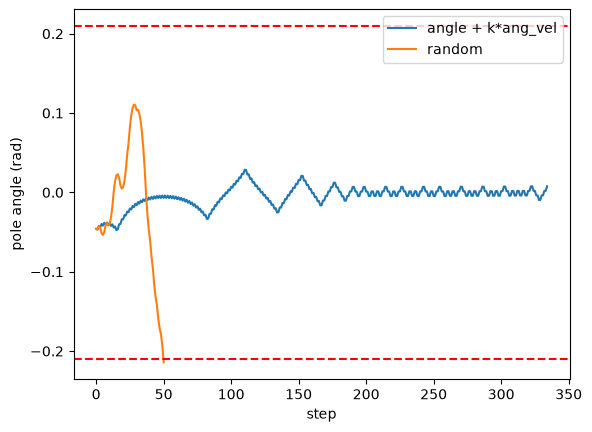

In [10]:
# Plot pole angle vs time for a good and a bad policy
def angle_trace(policy_fn, seed=0):
    env = gym.make("CartPole-v1")
    obs, _ = env.reset(seed=seed)
    angles, done = [obs[2]], False
    while not done:
        obs, _, terminated, truncated, _ = env.step(policy_fn(obs))
        angles.append(obs[2])
        done = terminated or truncated
    env.close()
    return angles

plt.plot(angle_trace(policy_combined), label="angle + k*ang_vel")
plt.plot(angle_trace(random_policy), label="random")
plt.axhline(0.2095, color="r", ls="--")
plt.axhline(-0.2095, color="r", ls="--")
plt.xlabel("step")
plt.ylabel("pole angle (rad)")
plt.legend()
plt.show()

In [11]:
# Q-table size if each variable is discretized into N bins
n_bins = 10  # TODO: try other values
n_states = n_bins ** 4
n_actions = 2
print(f"{n_bins} bins/variable -> {n_states:,} states x {n_actions} actions = {n_states * n_actions:,} Q-values")

10 bins/variable -> 10,000 states x 2 actions = 20,000 Q-values
